In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz

In [2]:
Fs = 10000
N = 31

Fc_low = 3000
Fc_high = 3000

window_type = 'hann'

print("Sampling Frequency:", Fs, "Hz")
print("Filter Length:", N)
print("Window Type:", window_type)

Sampling Frequency: 10000 Hz
Filter Length: 31
Window Type: hann


In [3]:
lowpass_coeff = firwin(
    numtaps=N,
    cutoff=Fc_low,
    window=window_type,
    pass_zero='lowpass',
    fs=Fs
)

print("Low-pass Filter Coefficients:")
print(lowpass_coeff)

Low-pass Filter Coefficients:
[ 0.00000000e+00  2.36294439e-04 -6.22213220e-04 -1.48904646e-03
  4.55351027e-03 -5.84801114e-18 -1.16227064e-02  1.04726495e-02
  1.47629668e-02 -3.30275566e-02  1.75440334e-17  6.31702710e-02
 -5.64178020e-02 -8.95165958e-02  2.99461575e-01  6.00077307e-01
  2.99461575e-01 -8.95165958e-02 -5.64178020e-02  6.31702710e-02
  1.75440334e-17 -3.30275566e-02  1.47629668e-02  1.04726495e-02
 -1.16227064e-02 -5.84801114e-18  4.55351027e-03 -1.48904646e-03
 -6.22213220e-04  2.36294439e-04  0.00000000e+00]


In [5]:
f_lp, H_lp = freqz(
    lowpass_coeff,
    worN=2048,
    fs=Fs
)

magnitude_lp = 20 * np.log10(
    np.maximum(np.abs(H_lp), 1e-10)
)

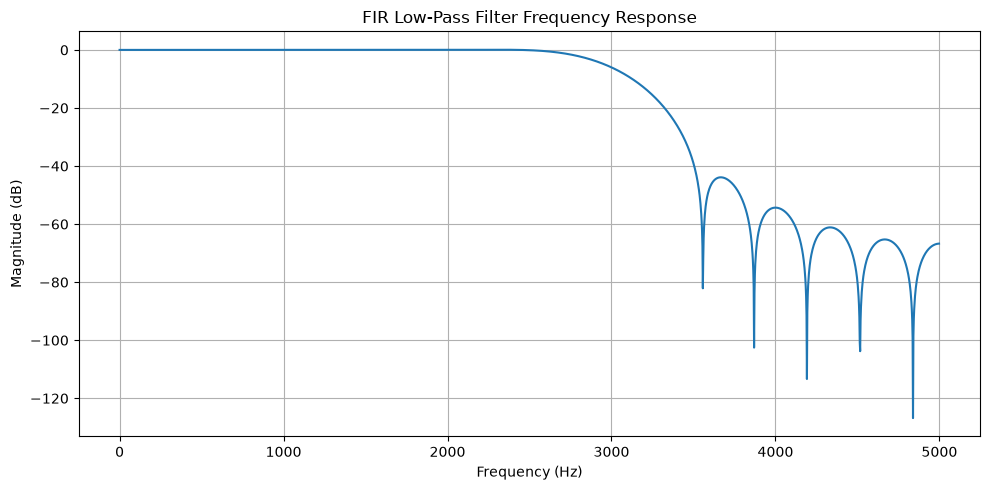

In [6]:
plt.figure(figsize=(10, 5))

plt.plot(f_lp, magnitude_lp)

plt.title("FIR Low-Pass Filter Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.grid(True)

plt.tight_layout()
plt.show()

In [8]:
highpass_coeff = firwin(
    numtaps=N,
    cutoff=3000,
    window='hann',
    pass_zero='highpass',
    fs=Fs
)

print("High-pass Filter Coefficients:")
print(highpass_coeff)

High-pass Filter Coefficients:
[ 0.00000000e+00 -2.36155069e-04  6.21846227e-04  1.48816819e-03
 -4.55082453e-03 -3.89637458e-18  1.16158511e-02 -1.04664726e-02
 -1.47542593e-02  3.30080763e-02  1.16891238e-17 -6.31330120e-02
  5.63845257e-02  8.94637973e-02 -2.99284947e-01  3.99815580e-01
 -2.99284947e-01  8.94637973e-02  5.63845257e-02 -6.31330120e-02
  1.16891238e-17  3.30080763e-02 -1.47542593e-02 -1.04664726e-02
  1.16158511e-02 -3.89637458e-18 -4.55082453e-03  1.48816819e-03
  6.21846227e-04 -2.36155069e-04  0.00000000e+00]


In [9]:
f_hp, H_hp = freqz(
    highpass_coeff,
    worN=2048,
    fs=Fs
)

magnitude_hp = 20 * np.log10(
    np.maximum(np.abs(H_hp), 1e-10)
)

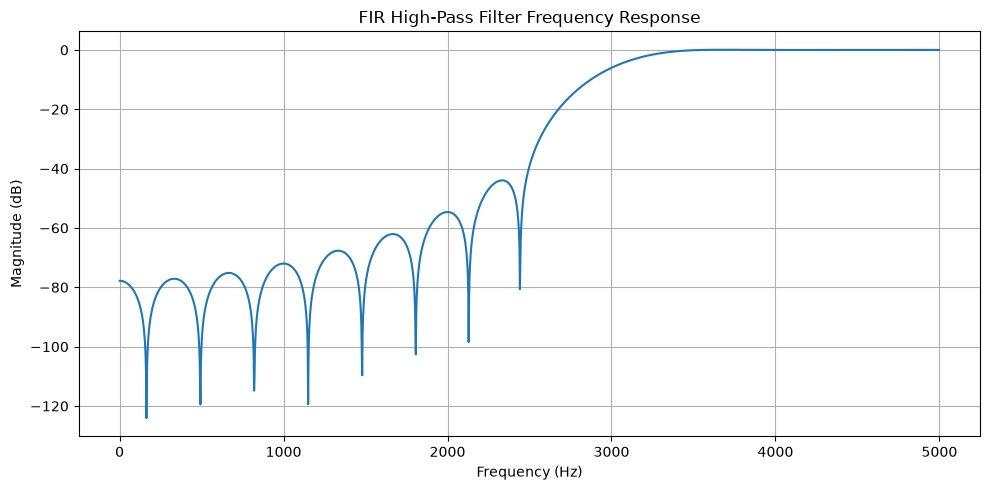

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(f_hp, magnitude_hp)

plt.title("FIR High-Pass Filter Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.grid(True)

plt.tight_layout()
plt.show()

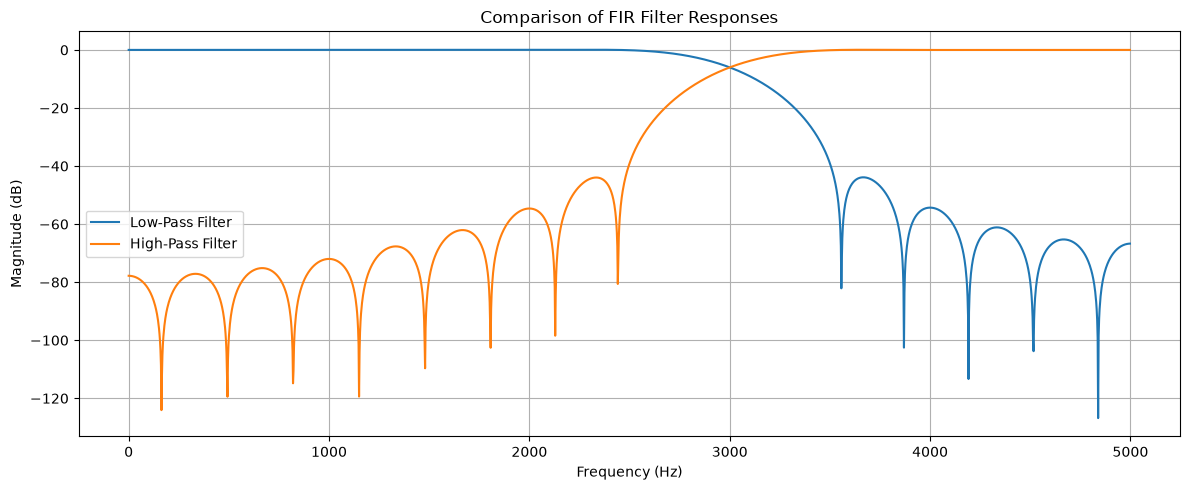

In [11]:
plt.figure(figsize=(12, 5))

plt.plot(f_lp, magnitude_lp, label="Low-Pass Filter")
plt.plot(f_hp, magnitude_hp, label="High-Pass Filter")

plt.title("Comparison of FIR Filter Responses")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [12]:
bandpass_coeff = firwin(
    numtaps=N,
    cutoff=[3000, 4000],
    window='hann',
    pass_zero='bandpass',
    fs=Fs
)

print("Band-Pass Filter Coefficients:")
print(bandpass_coeff)

Band-Pass Filter Coefficients:
[-0.00000000e+00 -3.90977655e-04  1.66580941e-03 -9.41090530e-04
 -1.77861453e-03 -1.99341505e-18  4.53986337e-03  6.61880711e-03
 -3.95238933e-02  5.46480766e-02 -4.18617160e-17 -1.04522834e-01
  1.51043569e-01 -5.65752802e-02 -1.16970574e-01  2.04548710e-01
 -1.16970574e-01 -5.65752802e-02  1.51043569e-01 -1.04522834e-01
 -4.18617160e-17  5.46480766e-02 -3.95238933e-02  6.61880711e-03
  4.53986337e-03 -1.99341505e-18 -1.77861453e-03 -9.41090530e-04
  1.66580941e-03 -3.90977655e-04 -0.00000000e+00]


In [13]:
f_bp, H_bp = freqz(
    bandpass_coeff,
    worN=2048,
    fs=Fs
)

magnitude_bp = 20 * np.log10(
    np.maximum(np.abs(H_bp), 1e-10)
)

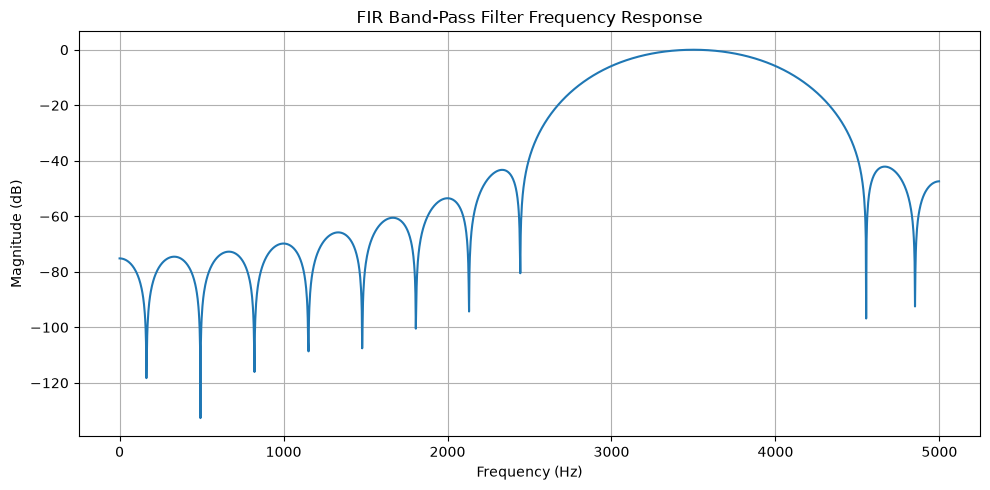

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(f_bp, magnitude_bp)

plt.title("FIR Band-Pass Filter Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.grid(True)

plt.tight_layout()
plt.show()

In [15]:
bandstop_coeff = firwin(
    numtaps=N,
    cutoff=[3000, 4000],
    window='hann',
    pass_zero='bandstop',
    fs=Fs
)

print("Band-Stop Filter Coefficients:")
print(bandstop_coeff)

Band-Stop Filter Coefficients:
[ 0.00000000e+00  3.82348390e-04 -1.62904334e-03  9.20319728e-04
  1.73935874e-03 -7.79767359e-18 -4.43966407e-03 -6.47272346e-03
  3.86515617e-02 -5.34419392e-02  7.01790623e-17  1.02215911e-01
 -1.47709887e-01  5.53266076e-02  1.14388917e-01  8.00136467e-01
  1.14388917e-01  5.53266076e-02 -1.47709887e-01  1.02215911e-01
  7.01790623e-17 -5.34419392e-02  3.86515617e-02 -6.47272346e-03
 -4.43966407e-03 -7.79767359e-18  1.73935874e-03  9.20319728e-04
 -1.62904334e-03  3.82348390e-04  0.00000000e+00]


In [16]:
f_bs, H_bs = freqz(
    bandstop_coeff,
    worN=2048,
    fs=Fs
)

magnitude_bs = 20 * np.log10(
    np.maximum(np.abs(H_bs), 1e-10)
)

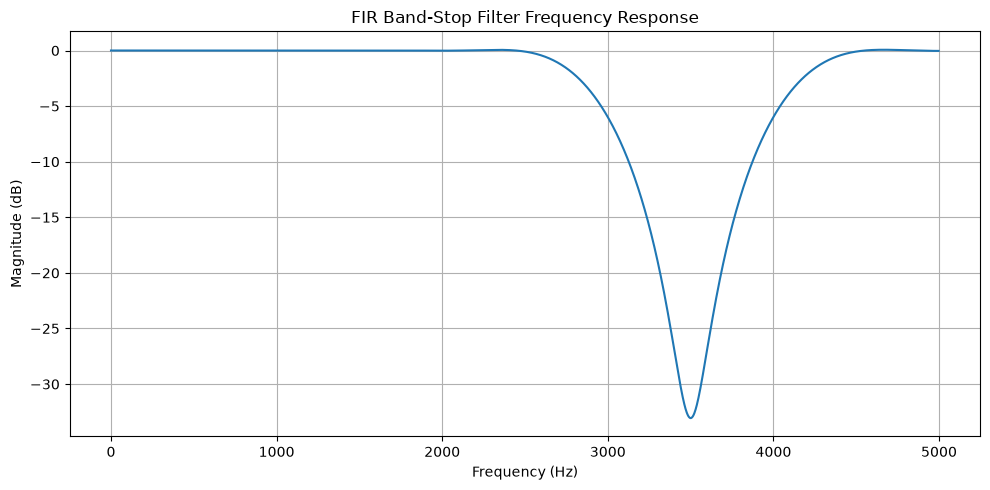

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(f_bs, magnitude_bs)

plt.title("FIR Band-Stop Filter Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.grid(True)

plt.tight_layout()
plt.show()

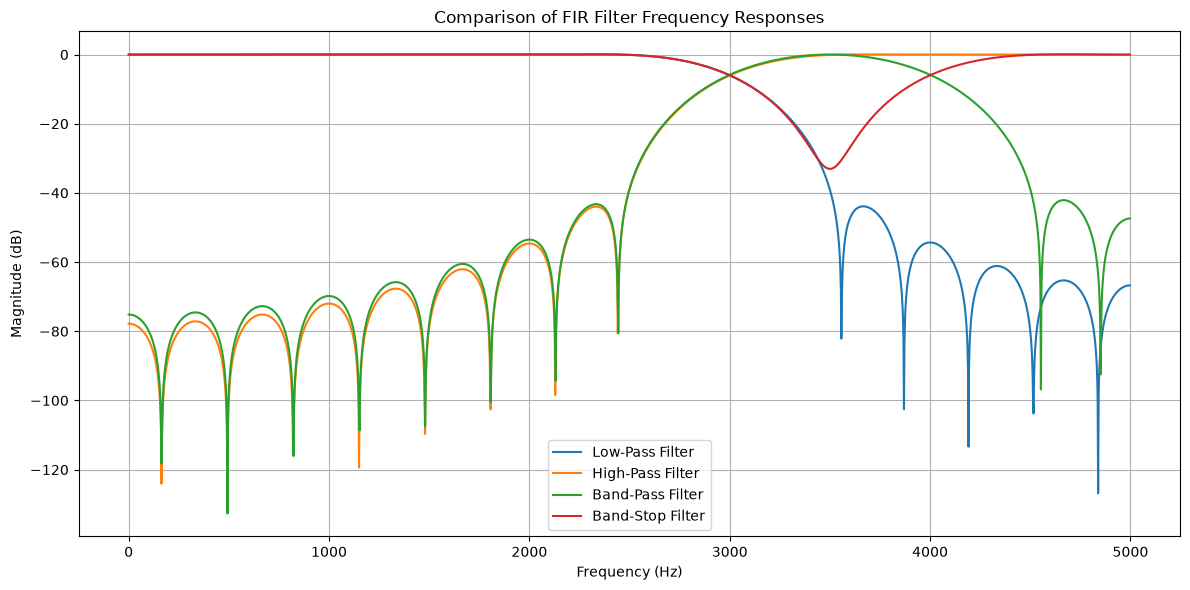

In [18]:
plt.figure(figsize=(12, 6))

plt.plot(f_lp, magnitude_lp, label="Low-Pass Filter")
plt.plot(f_hp, magnitude_hp, label="High-Pass Filter")
plt.plot(f_bp, magnitude_bp, label="Band-Pass Filter")
plt.plot(f_bs, magnitude_bs, label="Band-Stop Filter")

plt.title("Comparison of FIR Filter Frequency Responses")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
print("FIR LOW-PASS FILTER COEFFICIENTS")
print(lowpass_coeff)

print("\nFIR HIGH-PASS FILTER COEFFICIENTS")
print(highpass_coeff)

print("\nFIR BAND-PASS FILTER COEFFICIENTS")
print(bandpass_coeff)

print("\nFIR BAND-STOP FILTER COEFFICIENTS")
print(bandstop_coeff)

FIR LOW-PASS FILTER COEFFICIENTS
[ 0.00000000e+00  2.36294439e-04 -6.22213220e-04 -1.48904646e-03
  4.55351027e-03 -5.84801114e-18 -1.16227064e-02  1.04726495e-02
  1.47629668e-02 -3.30275566e-02  1.75440334e-17  6.31702710e-02
 -5.64178020e-02 -8.95165958e-02  2.99461575e-01  6.00077307e-01
  2.99461575e-01 -8.95165958e-02 -5.64178020e-02  6.31702710e-02
  1.75440334e-17 -3.30275566e-02  1.47629668e-02  1.04726495e-02
 -1.16227064e-02 -5.84801114e-18  4.55351027e-03 -1.48904646e-03
 -6.22213220e-04  2.36294439e-04  0.00000000e+00]

FIR HIGH-PASS FILTER COEFFICIENTS
[ 0.00000000e+00 -2.36155069e-04  6.21846227e-04  1.48816819e-03
 -4.55082453e-03 -3.89637458e-18  1.16158511e-02 -1.04664726e-02
 -1.47542593e-02  3.30080763e-02  1.16891238e-17 -6.31330120e-02
  5.63845257e-02  8.94637973e-02 -2.99284947e-01  3.99815580e-01
 -2.99284947e-01  8.94637973e-02  5.63845257e-02 -6.31330120e-02
  1.16891238e-17  3.30080763e-02 -1.47542593e-02 -1.04664726e-02
  1.16158511e-02 -3.89637458e-18 -4.5

In [21]:
print("FIR FILTER DESIGN SPECIFICATIONS")

print("Filter Length:", N)
print("Sampling Frequency:", Fs, "Hz")
print("Window Type:", window_type)

print("\nLow-Pass Cutoff: 3000 Hz")
print("High-Pass Cutoff: 3000 Hz")
print("Band-Pass Cutoffs: 3000 Hz - 4000 Hz")
print("Band-Stop Cutoffs: 3000 Hz - 4000 Hz")

FIR FILTER DESIGN SPECIFICATIONS
Filter Length: 31
Sampling Frequency: 10000 Hz
Window Type: hann

Low-Pass Cutoff: 3000 Hz
High-Pass Cutoff: 3000 Hz
Band-Pass Cutoffs: 3000 Hz - 4000 Hz
Band-Stop Cutoffs: 3000 Hz - 4000 Hz
